In [56]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import numpy as np

In [57]:
dir_vf = r"./uwhv/CSV/VF_Data.csv"
df_vf = pd.read_csv(dir_vf)
display(df_vf.head())

dir_coord = r"./uwhv/CSV/Coord_242.csv"
df_coord = pd.read_csv(dir_coord)
display(df_coord.head())
# display(df_coord)

# dir_summary = r"./uwhv/CSV/Series_Summary.csv"
# df_summary = pd.read_csv(dir_summary)
# display(df_summary.head())

,PatID,Gender,Eye,FieldN,Age,Time_from_Baseline,MS,MS_Cluster1,MS_Cluster2,MS_Cluster3,...,PD_45,PD_46,PD_47,PD_48,PD_49,PD_50,PD_51,PD_52,PD_53,PD_54
0,647,F,Right,1,52.7967,0.0000,27.832885,25.57750,26.979231,30.588333,...,-1.92,-0.36,-0.44,-1.52,-0.03,-1.06,0.75,-1.33,-2.02,-0.61
1,647,F,Right,2,53.8234,1.0267,30.131346,27.76000,29.911538,33.263333,...,-0.54,-1.13,-1.81,-1.74,-2.19,-1.23,-4.85,-2.24,0.00,0.28
2,647,F,Right,3,54.8857,2.0890,29.454808,25.47500,29.826154,32.488333,...,-0.07,1.56,-2.09,0.07,-0.84,-2.45,-0.48,-4.10,-1.28,-4.07
3,647,F,Right,4,57.7331,4.9363,27.947885,23.75625,28.658462,31.431667,...,-2.57,-1.74,-0.52,-2.70,-1.48,-3.32,-3.00,-6.49,-2.19,-2.76
4,647,F,Right,5,58.7680,5.9713,27.644038,24.90250,28.104615,30.105000,...,-0.80,-0.93,-3.08,-2.55,-3.26,-3.13,-1.42,-0.18,-1.02,-2.63


,X,Y,Cluster,LocID
0,-9,21,1,1
1,-3,21,1,2
2,3,21,1,3
3,9,21,1,4
4,-15,15,1,5


In [58]:
print([i for i in df_vf.columns])

['PatID', 'Gender', 'Eye', 'FieldN', 'Age', 'Time_from_Baseline', 'MS', 'MS_Cluster1', 'MS_Cluster2', 'MS_Cluster3', 'MS_Cluster4', 'MS_Cluster5', 'MS_Cluster6', 'MTD', 'PSD', 'MTD_Cluster1', 'MTD_Cluster2', 'MTD_Cluster3', 'MTD_Cluster4', 'MTD_Cluster5', 'MTD_Cluster6', 'GH', 'Sens_1', 'Sens_2', 'Sens_3', 'Sens_4', 'Sens_5', 'Sens_6', 'Sens_7', 'Sens_8', 'Sens_9', 'Sens_10', 'Sens_11', 'Sens_12', 'Sens_13', 'Sens_14', 'Sens_15', 'Sens_16', 'Sens_17', 'Sens_18', 'Sens_19', 'Sens_20', 'Sens_21', 'Sens_22', 'Sens_23', 'Sens_24', 'Sens_25', 'Sens_26', 'Sens_27', 'Sens_28', 'Sens_29', 'Sens_30', 'Sens_31', 'Sens_32', 'Sens_33', 'Sens_34', 'Sens_35', 'Sens_36', 'Sens_37', 'Sens_38', 'Sens_39', 'Sens_40', 'Sens_41', 'Sens_42', 'Sens_43', 'Sens_44', 'Sens_45', 'Sens_46', 'Sens_47', 'Sens_48', 'Sens_49', 'Sens_50', 'Sens_51', 'Sens_52', 'Sens_53', 'Sens_54', 'TD_1', 'TD_2', 'TD_3', 'TD_4', 'TD_5', 'TD_6', 'TD_7', 'TD_8', 'TD_9', 'TD_10', 'TD_11', 'TD_12', 'TD_13', 'TD_14', 'TD_15', 'TD_16', 'T

PatID: 患者識別番号

Gender: 患者の性別

Eye: laterality (Right/Left)横方向(右/左)

FieldN: sequential test number for each eye (time ordered)

Age: patient age at each test (years)

Time_from_Baseline: calculated as Age (at test N) - Age (at test 1)

MS: Mean Sensitivity

MS_Cluster1 to 6: MS for each cluster

MTD: Mean Total Deviation

PSD: Pattern Standard Deviation

MTD_Cluster1 to 6: MTD for each cluster

GH: General Height (7th highest TD value)

Sens_1 to 54: Sensitivity values for each location

TD_1 to 54: Total Deviation values for each location (missing for blind spot locations)

PD_1 to 54: Pattern Deviation values for each location (missing for blind spot locations)

In [59]:
print(len(df_vf["PatID"].unique()))
print(len(df_vf["Gender"].unique()))
print(len(df_vf["Eye"].unique()))
print(len(df_vf["PatID"].unique()))

3871
4
2
3871


In [60]:
df_vf["Gender"].unique()

<ArrowStringArray>
['F', 'M', nan, 'O']
Length: 4, dtype: str

In [61]:
import itertools

In [62]:
l_keys = ["Gender", "Eye"]
for i_key in l_keys:
    print("===", i_key, "===")
    for i_label in df_vf[i_key].unique():
        print(i_label, len(df_vf[df_vf[i_key]==i_label]))

print("====matrix====")
for i_gen, i_eye in itertools.product(df_vf["Gender"].unique(), df_vf["Eye"].unique()):

    print(i_gen, i_eye, len(df_vf[(df_vf["Gender"]==i_gen)&(df_vf["Eye"]==i_eye)]))

=== Gender ===
F 12815
M 10582
nan 0
O 17
=== Eye ===
Right 14433
Left 14510
====matrix====
F Right 6381
F Left 6434
M Right 5290
M Left 5292
nan Right 0
nan Left 0
O Right 8
O Left 9


数が多く右目の`F Right 6381`条件でまずは確かめる

In [63]:
display(df_vf[(df_vf["Gender"]=="F")&(df_vf["Eye"]=="Right")&(df_vf["PatID"]==647)])

,PatID,Gender,Eye,FieldN,Age,Time_from_Baseline,MS,MS_Cluster1,MS_Cluster2,MS_Cluster3,...,PD_45,PD_46,PD_47,PD_48,PD_49,PD_50,PD_51,PD_52,PD_53,PD_54
0,647,F,Right,1,52.7967,0.0000,27.832885,25.57750,26.979231,30.588333,...,-1.92,-0.36,-0.44,-1.52,-0.03,-1.06,0.75,-1.33,-2.02,-0.61
1,647,F,Right,2,53.8234,1.0267,30.131346,27.76000,29.911538,33.263333,...,-0.54,-1.13,-1.81,-1.74,-2.19,-1.23,-4.85,-2.24,0.00,0.28
2,647,F,Right,3,54.8857,2.0890,29.454808,25.47500,29.826154,32.488333,...,-0.07,1.56,-2.09,0.07,-0.84,-2.45,-0.48,-4.10,-1.28,-4.07
3,647,F,Right,4,57.7331,4.9363,27.947885,23.75625,28.658462,31.431667,...,-2.57,-1.74,-0.52,-2.70,-1.48,-3.32,-3.00,-6.49,-2.19,-2.76
4,647,F,Right,5,58.7680,5.9713,27.644038,24.90250,28.104615,30.105000,...,-0.80,-0.93,-3.08,-2.55,-3.26,-3.13,-1.42,-0.18,-1.02,-2.63
5,647,F,Right,6,62.5243,9.7276,28.814615,25.96875,28.509231,31.263333,...,-0.13,-0.30,-0.70,-1.43,-1.39,-4.04,-0.48,-0.29,-2.78,-2.02
6,647,F,Right,7,63.7892,10.9925,27.219038,22.46375,26.590769,30.396667,...,-0.51,0.82,-1.06,-2.96,-1.64,-1.94,0.00,-1.35,-0.10,-0.62
7,647,F,Right,8,64.2491,11.4524,28.433077,25.63250,28.636154,31.310000,...,-2.53,-3.12,-0.27,-1.90,0.49,0.53,-3.08,-2.30,-0.42,-3.38
8,647,F,Right,9,65.7440,12.9473,28.275385,25.27500,28.032308,30.880000,...,-2.67,-0.38,0.61,0.07,-1.39,-4.09,1.09,-2.52,-3.33,-0.47
9,647,F,Right,10,66.8063,14.0096,28.166923,23.00500,26.757692,33.136667,...,-2.28,-3.27,1.18,2.13,0.00,-3.26,-0.13,-3.32,-2.03,-4.01


両眼検査している人は2データ分積み重ねている。データは奇数件なので後々影響が出そう。

`display(df_vf[(df_vf["Gender"]=="F")&(df_vf["PatID"]==647)])`

In [64]:
# 両眼が同じ試験回数
l_num_eyes = []
for i_id in df_vf["PatID"].unique():
    df_slice = df_vf[df_vf["PatID"]==i_id]
    l_num_eyes.append((len(df_slice[df_slice["Eye"]=="Right"]), len(df_slice[df_slice["Eye"]=="Left"]), df_slice["PatID"].iloc[0]))

l_num_eyes_same = [i for i in l_num_eyes if i[0]==i[1]]

print(len(l_num_eyes_same))
print(len(l_num_eyes_same)/len(l_num_eyes))

3083
0.7964350297080858


In [65]:
# 偏っているデータのうち、トレーニングに使えるもの。両目とも4件以上なら。
l_num_eyes_not_same = [i for i in l_num_eyes if i[0]!=i[1]]
print(l_num_eyes_not_same[0])
l_num_eyes_not_same_over4 = [i for i in l_num_eyes_not_same if (i[0]>3)and(i[1]>3)]
print(len(l_num_eyes_not_same))
print(len(l_num_eyes_not_same_over4))
print(l_num_eyes_not_same_over4[0])

df_slice_eye_not_same = df_vf[df_vf["PatID"]==l_num_eyes_not_same_over4[0][2]]
bool_same_place = df_slice_eye_not_same["FieldN"].duplicated(keep=False)
display(df_slice_eye_not_same[bool_same_place])

(2, 0, np.int64(1304))
788
303
(5, 4, np.int64(3597))


,PatID,Gender,Eye,FieldN,Age,Time_from_Baseline,MS,MS_Cluster1,MS_Cluster2,MS_Cluster3,...,PD_45,PD_46,PD_47,PD_48,PD_49,PD_50,PD_51,PD_52,PD_53,PD_54
219,3597,F,Right,1,64.5777,0.0000,28.653654,25.19750,28.372308,32.520000,...,-3.18,-3.67,-2.17,-1.14,-3.80,-1.15,-3.56,-3.01,-3.00,-3.86
220,3597,F,Right,2,65.0760,0.4983,30.100192,28.16500,30.953846,32.426667,...,-4.40,-3.63,-2.78,-3.48,-3.61,-7.42,-2.67,-5.41,-6.88,-9.36
221,3597,F,Right,3,68.7556,4.1780,18.779038,12.91125,18.923077,28.381667,...,-11.94,-9.58,-9.64,-3.39,-6.50,-8.20,-16.90,-12.58,-4.05,-8.75
222,3597,F,Right,4,68.8131,4.2355,24.935192,22.06750,26.676923,29.010000,...,-10.43,-2.01,-3.21,-3.48,-3.68,-7.73,-13.12,-10.39,-6.99,-5.04
224,3597,F,Left,1,64.5777,0.0000,30.101923,25.86875,28.997692,33.413333,...,-1.33,-0.12,-1.62,0.54,-0.20,-0.14,-1.82,-4.45,-1.00,-0.05
225,3597,F,Left,2,65.0760,0.4983,29.929231,28.25625,29.280000,31.700000,...,4.36,-1.21,-1.37,-1.50,-0.58,-0.64,-5.13,-1.49,-3.80,-5.19
226,3597,F,Left,3,68.7556,4.1780,22.125000,18.99375,21.947692,25.798333,...,-7.33,-3.42,-2.68,-1.68,-2.33,-3.03,-2.16,-2.73,-0.61,0.73
227,3597,F,Left,4,69.0705,4.4928,27.690000,22.80625,27.481538,30.626667,...,-2.52,-0.41,-2.05,-1.61,-3.57,-1.98,-3.57,-3.50,-3.98,-2.73


## データの確認

基本は`Sens_xx`のデータを用いる

In [66]:
df_vf.columns

Index(['PatID', 'Gender', 'Eye', 'FieldN', 'Age', 'Time_from_Baseline', 'MS',
       'MS_Cluster1', 'MS_Cluster2', 'MS_Cluster3',
       ...
       'PD_45', 'PD_46', 'PD_47', 'PD_48', 'PD_49', 'PD_50', 'PD_51', 'PD_52',
       'PD_53', 'PD_54'],
      dtype='str', length=184)

In [67]:
l_col_sens = [i for i in df_vf.columns if "Sens_" in i]
# l_col_sens

In [68]:
df_coord

,X,Y,Cluster,LocID
0,-9,21,1,1
1,-3,21,1,2
2,3,21,1,3
3,9,21,1,4
4,-15,15,1,5
5,-9,15,2,6
6,-3,15,2,7
7,3,15,2,8
8,9,15,1,9
9,15,15,1,10


In [69]:
l_col_td = [i for i in df_vf.columns if "TD_" in i]
(df_vf[l_col_td]==100).sum().max()

np.int64(0)

In [70]:
type(data_vf_slice)

pandas.DataFrame

In [71]:
df_vf[l_col_sens]

,Sens_1,Sens_2,Sens_3,Sens_4,Sens_5,Sens_6,Sens_7,Sens_8,Sens_9,Sens_10,...,Sens_45,Sens_46,Sens_47,Sens_48,Sens_49,Sens_50,Sens_51,Sens_52,Sens_53,Sens_54
0,26.34,23.73,22.84,24.19,26.25,27.22,25.67,26.18,27.01,26.24,...,26.88,29.43,29.82,28.64,29.81,28.24,28.88,27.30,26.82,28.18
1,27.97,26.32,28.60,26.22,28.15,30.42,27.30,29.85,28.97,26.01,...,31.05,31.45,31.24,31.21,30.44,30.86,26.07,29.18,31.64,31.86
2,22.52,21.09,23.05,23.39,30.01,30.41,28.23,28.12,28.54,27.19,...,31.11,33.74,30.56,32.62,31.38,29.24,30.04,26.92,29.96,27.10
3,23.07,20.61,21.03,20.71,29.04,27.68,27.84,26.33,25.50,22.30,...,27.55,29.39,31.08,28.79,29.69,27.30,26.46,23.49,27.99,27.35
4,24.83,22.88,26.14,22.95,25.07,27.33,26.46,26.39,25.75,24.18,...,28.19,29.09,27.40,27.82,26.79,26.37,26.92,28.68,28.04,26.36
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
28938,21.56,25.15,26.69,25.96,22.65,22.94,25.67,26.98,26.63,24.57,...,29.71,26.58,26.24,27.36,29.60,29.20,28.78,26.51,28.68,27.39
28939,27.05,28.78,28.58,20.72,22.66,28.18,30.03,29.34,28.29,27.04,...,29.85,30.71,28.34,31.73,30.80,31.86,25.73,28.05,30.70,28.24
28940,24.31,25.05,21.18,19.61,25.27,26.91,26.69,23.08,22.36,25.97,...,29.12,29.42,30.01,30.78,30.09,27.70,29.74,26.02,27.40,28.22
28941,27.15,28.71,26.94,25.93,28.09,29.09,30.05,28.06,25.86,26.40,...,25.15,26.05,22.07,25.15,28.12,28.26,26.69,26.33,27.21,29.84


PatID         647
Gender          F
Eye         Right
FieldN          1
Age       52.7967
           ...   
PD_50       -1.06
PD_51        0.75
PD_52       -1.33
PD_53       -2.02
PD_54       -0.61
Name: 0, Length: 184, dtype: object

/tmp/ipykernel_69206/1197326988.py:31: UserWarning: The pixel maker ',' is not supported on scatter(); using a finite-sized square instead, which is not necessarily 1 pixel in size. Use the square marker 's' instead to suppress this warning.
  sc = ax.scatter(


[]

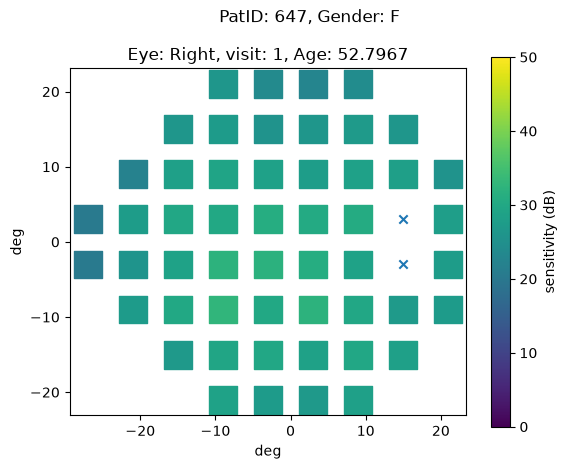

In [72]:
df_data_slice = df_vf.iloc[0]
data_vf_slice = df_data_slice[l_col_sens]
display(df_data_slice)
# display(data_vf_slice)
# display(df_coord)

sens_max = df_vf[l_col_sens].max().max()
sens_min = df_vf[l_col_sens].min().min()

df_not_blind = df_coord["Cluster"]!=0
df_blind = df_coord["Cluster"]==0

# print(df_blind.shape)
# print(df_coord["X"].shape)
# print(df_coord["Y"].shape)
# print(data_vf_slice.shape)

# for i_loc in l_col_sens:
#     print(data_vf_slice[i_loc])
#     i_loc_vf = df_coord["LocID"]==int(i_loc.replace("Sens_",""))
#     display(df_coord[i_loc_vf])
#     break
# 'PatID', 'Gender', 'Eye', 'FieldN', 'Age'
fig = plt.figure()

s_suptitle = f"PatID: {df_data_slice["PatID"]}, Gender: {df_data_slice["Gender"]}"
fig.suptitle(s_suptitle)

ax = fig.add_subplot(111, xlabel="deg", ylabel='deg')
ax.set_aspect("equal")
sc = ax.scatter(
    df_coord["X"][df_not_blind], 
    df_coord["Y"][df_not_blind], 
    c=data_vf_slice.to_numpy()[df_not_blind], # Booleanマスクのindexが異なる場合は.to_numpy() # chatgpt
    s=400, 
    vmax=sens_max, vmin=sens_min, marker=",")#, linewidths=10)
fig.colorbar(sc, ax=ax).set_label("sensitivity (dB)")

ax.scatter(df_coord["X"][df_blind], df_coord["Y"][df_blind], marker="x")
s_ax_title = f"Eye: {df_data_slice["Eye"]}, visit: {df_data_slice["FieldN"]}, Age: {df_data_slice["Age"]}"
ax.set_title(s_ax_title)

plt.plot()

/tmp/ipykernel_69206/3413314307.py:33: UserWarning: The pixel maker ',' is not supported on scatter(); using a finite-sized square instead, which is not necessarily 1 pixel in size. Use the square marker 's' instead to suppress this warning.
  sc = axes[0,0].scatter(


[]

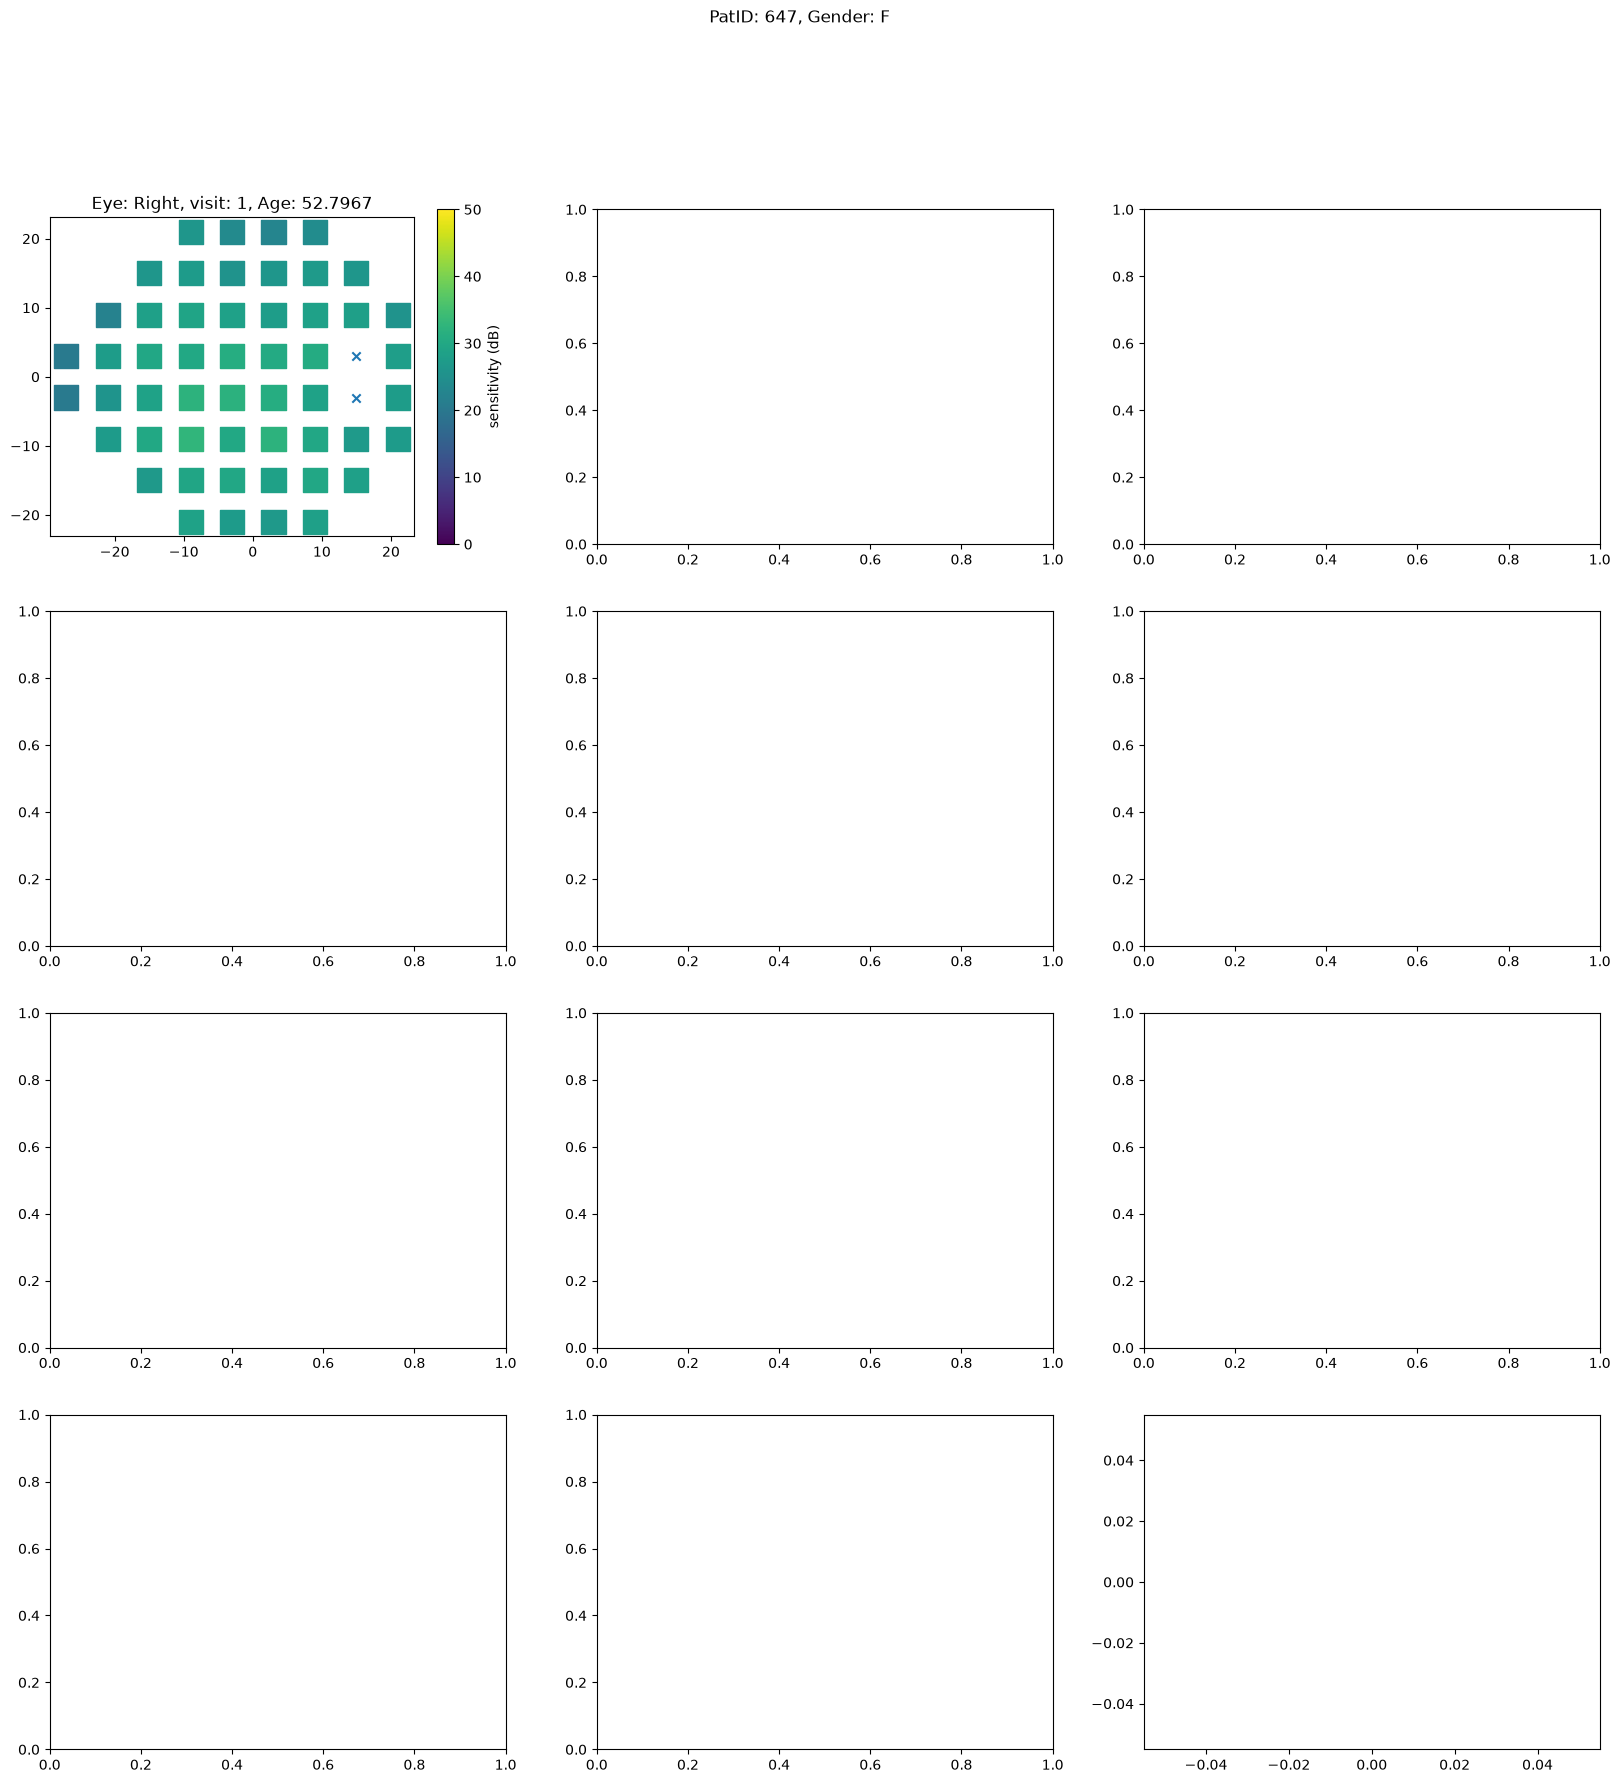

In [73]:
df_data_slice = df_vf.iloc[0]
data_vf_slice = df_data_slice[l_col_sens]
# display(df_data_slice)
# display(data_vf_slice)
# display(df_coord)

sens_max = df_vf[l_col_sens].max().max()
sens_min = df_vf[l_col_sens].min().min()

df_not_blind = df_coord["Cluster"]!=0
df_blind = df_coord["Cluster"]==0

# print(df_blind.shape)
# print(df_coord["X"].shape)
# print(df_coord["Y"].shape)
# print(data_vf_slice.shape)

# for i_loc in l_col_sens:
#     print(data_vf_slice[i_loc])
#     i_loc_vf = df_coord["LocID"]==int(i_loc.replace("Sens_",""))
#     display(df_coord[i_loc_vf])
#     break
# 'PatID', 'Gender', 'Eye', 'FieldN', 'Age'
fig = plt.figure(figsize=(20,20))

s_suptitle = f"PatID: {df_data_slice["PatID"]}, Gender: {df_data_slice["Gender"]}"
fig.suptitle(s_suptitle)

axes = fig.subplots(4, 3)

# axes[0] = fig.add_subplot(111, xlabel="deg", ylabel='deg')
axes[0,0].set_aspect("equal")
sc = axes[0,0].scatter(
    df_coord["X"][df_not_blind], 
    df_coord["Y"][df_not_blind], 
    c=data_vf_slice.to_numpy()[df_not_blind], # Booleanマスクのindexが異なる場合は.to_numpy() # chatgpt
    s=300, 
    vmax=sens_max, vmin=sens_min, marker=",")#, linewidths=10)
fig.colorbar(sc, ax=axes[0,0]).set_label("sensitivity (dB)")

axes[0,0].scatter(df_coord["X"][df_blind], df_coord["Y"][df_blind], marker="x")
s_ax_title = f"Eye: {df_data_slice["Eye"]}, visit: {df_data_slice["FieldN"]}, Age: {df_data_slice["Age"]}"
axes[0,0].set_title(s_ax_title)

plt.plot()

In [74]:
df_not_blind = df_coord["Cluster"]!=0
df_col_sens_not_blind = np.array(l_col_sens)[df_not_blind]
df_vf.groupby(["PatID", "Eye", "Age"])[df_col_sens_not_blind].mean()

Sens_1  Sens_2  Sens_3  Sens_4  Sens_5  Sens_6  Sens_7  \
PatID Eye   Age                                                               
1     Left  78.9432    0.00   17.28    0.00    0.00   18.56   23.22   18.50   
            84.3012   10.91    0.00    8.17    0.00   10.38   17.45   19.54   
            85.7577   11.39    9.22    0.00    9.84   21.63   22.58   21.49   
            86.8884    7.36    0.46    2.58    0.00   14.87   20.58   13.83   
            87.9425    9.16   10.33    0.00   16.29   18.53   21.84   22.88   
...                     ...     ...     ...     ...     ...     ...     ...   
8393  Right 75.2799   28.49   26.80   27.80   26.52   23.94   25.83   27.17   
            76.2765   26.12   26.16   24.92   24.45   27.92   27.49   28.38   
            77.2731   25.38   27.89   28.88   28.11   29.23   30.74   29.27   
8547  Left  54.8775   25.73   21.14   24.93   26.83   25.42   28.66   26.28   
            55.3758   26.09   25.40   27.39   17.85   31.62   27.37   26.94   

                     Sens_8  Sens_9  Sens_10  ...  Sens_45  Sens_46  Sens_47  \
PatID Eye   Age                               ...                              
1     Left  78.9432   18.18   24.62    20.47  ...    26.46    24.62    26.55   
            84.3012   19.12   20.85    24.91  ...    28.72    26.01    26.97   
            85.7577    9.78   22.63    18.32  ...    18.58    24.46    24.09   
            86.8884   14.79   18.03    15.04  ...    21.03    22.04    22.37   
            87.9425   17.60   23.32    20.91  ...    18.54    24.94    23.33   
...                     ...     ...      ...  ...      ...      ...      ...   
8393  Right 75.2799   26.51   26.08    27.32  ...    26.68    27.82    25.72   
            76.2765   24.16   25.49    24.80  ...    28.94    28.78    26.12   
            77.2731   31.58   30.84    28.20  ...    28.92    29.04    27.14   
8547  Left  54.8775   24.97   27.30    28.81  ...    21.47    24.73    26.49   
            55.3758   28.06   25.00    24.63  ...    26.79    26.43    26.43   

                     Sens_48  Sens_49  Sens_50  Sens_51  Sens_52  Sens_53  \
PatID Eye   Age                                                             
1     Left  78.9432    25.64    27.94    25.88    19.83    21.34    24.01   
            84.3012    28.99    28.48    27.37    22.36    27.00    26.60   
            85.7577    23.89    26.36    25.56    20.16    22.24    22.99   
            86.8884    21.79    24.84    21.66    20.71    16.94    17.06   
            87.9425    24.89    25.05    24.59    19.96    18.49    22.97   
...                      ...      ...      ...      ...      ...      ...   
8393  Right 75.2799    24.80    27.85    28.93    24.67    22.60    29.68   
            76.2765    27.67    27.74    22.37    27.93    27.11    26.55   
            77.2731    24.09    27.55    24.92    28.71    22.84    17.73   
8547  Left  54.8775    28.36    29.87    31.77    26.61    25.67    28.01   
            55.3758    28.69    30.03    31.80    24.97    17.28    23.82   

                     Sens_54  
PatID Eye   Age               
1     Left  78.9432    25.91  
            84.3012    24.33  
            85.7577    19.08  
            86.8884    24.69  
            87.9425    21.99  
...                      ...  
8393  Right 75.2799    27.78  
            76.2765    25.52  
            77.2731    21.56  
8547  Left  54.8775    25.99  
            55.3758    28.96  

[28943 rows x 52 columns]

In [75]:
df_vf.groupby(["PatID", "Eye",])[df_vf["Age"].duplicated(keep=False)]

KeyError: 'Columns not found: False, True'

In [76]:
df_vf[df_vf["Age"].duplicated(keep=False)]

,PatID,Gender,Eye,FieldN,Age,Time_from_Baseline,MS,MS_Cluster1,MS_Cluster2,MS_Cluster3,...,PD_45,PD_46,PD_47,PD_48,PD_49,PD_50,PD_51,PD_52,PD_53,PD_54
0,647,F,Right,1,52.7967,0.0000,27.832885,25.57750,26.979231,30.588333,...,-1.92,-0.36,-0.44,-1.52,-0.03,-1.06,0.75,-1.33,-2.02,-0.61
1,647,F,Right,2,53.8234,1.0267,30.131346,27.76000,29.911538,33.263333,...,-0.54,-1.13,-1.81,-1.74,-2.19,-1.23,-4.85,-2.24,0.00,0.28
2,647,F,Right,3,54.8857,2.0890,29.454808,25.47500,29.826154,32.488333,...,-0.07,1.56,-2.09,0.07,-0.84,-2.45,-0.48,-4.10,-1.28,-4.07
3,647,F,Right,4,57.7331,4.9363,27.947885,23.75625,28.658462,31.431667,...,-2.57,-1.74,-0.52,-2.70,-1.48,-3.32,-3.00,-6.49,-2.19,-2.76
4,647,F,Right,5,58.7680,5.9713,27.644038,24.90250,28.104615,30.105000,...,-0.80,-0.93,-3.08,-2.55,-3.26,-3.13,-1.42,-0.18,-1.02,-2.63
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
28938,7324,F,Left,2,65.6537,0.2163,27.471923,25.32125,25.657692,30.785000,...,0.30,-3.89,-4.68,-3.45,-0.88,-0.72,0.00,-2.81,-0.83,-2.02
28939,6859,M,Right,1,79.4114,0.0000,23.916346,26.37000,15.611538,15.225000,...,-0.43,-0.71,-3.52,0.00,-0.60,1.05,-3.96,-2.23,0.25,-2.06
28940,6859,M,Right,2,80.6598,1.2485,23.475192,23.74500,13.599231,22.355000,...,0.00,-0.85,-0.70,0.20,-0.16,-1.95,1.20,-3.11,-1.91,-0.93
28941,1142,NaN,Left,1,67.3155,0.0000,27.896923,26.95250,29.080000,30.493333,...,-4.77,-4.94,-9.38,-6.18,-2.88,-2.18,-2.61,-3.51,-2.83,-0.09


In [77]:
df_vf[df_vf["PatID"]==647]["Age"].duplicated(keep=False)

0     True
1     True
2     True
3     True
4     True
5     True
6     True
7     True
8     True
9     True
10    True
11    True
12    True
13    True
14    True
15    True
16    True
17    True
18    True
19    True
20    True
21    True
Name: Age, dtype: bool

In [78]:
import os
from tqdm import tqdm

In [79]:
dir_save = "./imgs"
os.makedirs(dir_save, exist_ok=True)

In [80]:
l_num_eyes_not_same = [i for i in l_num_eyes if i[0]!=i[1]]
print(l_num_eyes_not_same[0])
l_num_eyes_not_same_over4 = [i for i in l_num_eyes_not_same if (i[0]>3)and(i[1]>3)]
print(len(l_num_eyes_not_same))
print(len(l_num_eyes_not_same_over4))
print(l_num_eyes_not_same_over4[0])

df_slice_eye_not_same = df_vf[df_vf["PatID"]==l_num_eyes_not_same_over4[0][2]]
bool_same_place = df_slice_eye_not_same["FieldN"].duplicated(keep=False)
display(df_slice_eye_not_same[bool_same_place])


l_num_eyes_over4 = [i for i in l_num_eyes if (i[0]>3)and(i[1]>3)and(i[0]!=i[1])]

(2, 0, np.int64(1304))
788
303
(5, 4, np.int64(3597))


,PatID,Gender,Eye,FieldN,Age,Time_from_Baseline,MS,MS_Cluster1,MS_Cluster2,MS_Cluster3,...,PD_45,PD_46,PD_47,PD_48,PD_49,PD_50,PD_51,PD_52,PD_53,PD_54
219,3597,F,Right,1,64.5777,0.0000,28.653654,25.19750,28.372308,32.520000,...,-3.18,-3.67,-2.17,-1.14,-3.80,-1.15,-3.56,-3.01,-3.00,-3.86
220,3597,F,Right,2,65.0760,0.4983,30.100192,28.16500,30.953846,32.426667,...,-4.40,-3.63,-2.78,-3.48,-3.61,-7.42,-2.67,-5.41,-6.88,-9.36
221,3597,F,Right,3,68.7556,4.1780,18.779038,12.91125,18.923077,28.381667,...,-11.94,-9.58,-9.64,-3.39,-6.50,-8.20,-16.90,-12.58,-4.05,-8.75
222,3597,F,Right,4,68.8131,4.2355,24.935192,22.06750,26.676923,29.010000,...,-10.43,-2.01,-3.21,-3.48,-3.68,-7.73,-13.12,-10.39,-6.99,-5.04
224,3597,F,Left,1,64.5777,0.0000,30.101923,25.86875,28.997692,33.413333,...,-1.33,-0.12,-1.62,0.54,-0.20,-0.14,-1.82,-4.45,-1.00,-0.05
225,3597,F,Left,2,65.0760,0.4983,29.929231,28.25625,29.280000,31.700000,...,4.36,-1.21,-1.37,-1.50,-0.58,-0.64,-5.13,-1.49,-3.80,-5.19
226,3597,F,Left,3,68.7556,4.1780,22.125000,18.99375,21.947692,25.798333,...,-7.33,-3.42,-2.68,-1.68,-2.33,-3.03,-2.16,-2.73,-0.61,0.73
227,3597,F,Left,4,69.0705,4.4928,27.690000,22.80625,27.481538,30.626667,...,-2.52,-0.41,-2.05,-1.61,-3.57,-1.98,-3.57,-3.50,-3.98,-2.73


In [81]:
df_slice_eye_not_same = df_vf[df_vf["PatID"]==l_num_eyes_not_same_over4[0][2]]
display(df_slice_eye_not_same)

# 多分、両眼の記録として処理するならこれがいい
df_filtered = df_slice_eye_not_same[
    df_slice_eye_not_same.groupby(["PatID", "Age"])["Eye"].transform("nunique") == 2
]
display(df_filtered)

# bool_same_place = df_slice_eye_not_same["Age"].duplicated(keep=False)
# display(df_slice_eye_not_same[bool_same_place])

,PatID,Gender,Eye,FieldN,Age,Time_from_Baseline,MS,MS_Cluster1,MS_Cluster2,MS_Cluster3,...,PD_45,PD_46,PD_47,PD_48,PD_49,PD_50,PD_51,PD_52,PD_53,PD_54
219,3597,F,Right,1,64.5777,0.0000,28.653654,25.19750,28.372308,32.520000,...,-3.18,-3.67,-2.17,-1.14,-3.80,-1.15,-3.56,-3.01,-3.00,-3.86
220,3597,F,Right,2,65.0760,0.4983,30.100192,28.16500,30.953846,32.426667,...,-4.40,-3.63,-2.78,-3.48,-3.61,-7.42,-2.67,-5.41,-6.88,-9.36
221,3597,F,Right,3,68.7556,4.1780,18.779038,12.91125,18.923077,28.381667,...,-11.94,-9.58,-9.64,-3.39,-6.50,-8.20,-16.90,-12.58,-4.05,-8.75
222,3597,F,Right,4,68.8131,4.2355,24.935192,22.06750,26.676923,29.010000,...,-10.43,-2.01,-3.21,-3.48,-3.68,-7.73,-13.12,-10.39,-6.99,-5.04
223,3597,F,Right,5,69.0705,4.4928,23.261154,19.49500,25.153077,29.443333,...,-12.85,-4.80,-4.62,-4.81,-1.92,-4.24,-7.24,-20.70,-5.75,-6.74
224,3597,F,Left,1,64.5777,0.0000,30.101923,25.86875,28.997692,33.413333,...,-1.33,-0.12,-1.62,0.54,-0.20,-0.14,-1.82,-4.45,-1.00,-0.05
225,3597,F,Left,2,65.0760,0.4983,29.929231,28.25625,29.280000,31.700000,...,4.36,-1.21,-1.37,-1.50,-0.58,-0.64,-5.13,-1.49,-3.80,-5.19
226,3597,F,Left,3,68.7556,4.1780,22.125000,18.99375,21.947692,25.798333,...,-7.33,-3.42,-2.68,-1.68,-2.33,-3.03,-2.16,-2.73,-0.61,0.73
227,3597,F,Left,4,69.0705,4.4928,27.690000,22.80625,27.481538,30.626667,...,-2.52,-0.41,-2.05,-1.61,-3.57,-1.98,-3.57,-3.50,-3.98,-2.73


,PatID,Gender,Eye,FieldN,Age,Time_from_Baseline,MS,MS_Cluster1,MS_Cluster2,MS_Cluster3,...,PD_45,PD_46,PD_47,PD_48,PD_49,PD_50,PD_51,PD_52,PD_53,PD_54
219,3597,F,Right,1,64.5777,0.0000,28.653654,25.19750,28.372308,32.520000,...,-3.18,-3.67,-2.17,-1.14,-3.80,-1.15,-3.56,-3.01,-3.00,-3.86
220,3597,F,Right,2,65.0760,0.4983,30.100192,28.16500,30.953846,32.426667,...,-4.40,-3.63,-2.78,-3.48,-3.61,-7.42,-2.67,-5.41,-6.88,-9.36
221,3597,F,Right,3,68.7556,4.1780,18.779038,12.91125,18.923077,28.381667,...,-11.94,-9.58,-9.64,-3.39,-6.50,-8.20,-16.90,-12.58,-4.05,-8.75
223,3597,F,Right,5,69.0705,4.4928,23.261154,19.49500,25.153077,29.443333,...,-12.85,-4.80,-4.62,-4.81,-1.92,-4.24,-7.24,-20.70,-5.75,-6.74
224,3597,F,Left,1,64.5777,0.0000,30.101923,25.86875,28.997692,33.413333,...,-1.33,-0.12,-1.62,0.54,-0.20,-0.14,-1.82,-4.45,-1.00,-0.05
225,3597,F,Left,2,65.0760,0.4983,29.929231,28.25625,29.280000,31.700000,...,4.36,-1.21,-1.37,-1.50,-0.58,-0.64,-5.13,-1.49,-3.80,-5.19
226,3597,F,Left,3,68.7556,4.1780,22.125000,18.99375,21.947692,25.798333,...,-7.33,-3.42,-2.68,-1.68,-2.33,-3.03,-2.16,-2.73,-0.61,0.73
227,3597,F,Left,4,69.0705,4.4928,27.690000,22.80625,27.481538,30.626667,...,-2.52,-0.41,-2.05,-1.61,-3.57,-1.98,-3.57,-3.50,-3.98,-2.73


In [82]:
for i_id in df_vf["PatID"].unique():
    
    df_slice = df_vf[df_vf["PatID"]==i_id]
    
    

## 1人の患者の両眼と検査の推移（3 × 3）

この節の3つのコードセルは、上から順に実行するだけで画像を保存できます。
前の探索セルを実行する必要はありません。`patient_id` を変更すると、別の患者を表示できます。
対象は **左眼・右眼のそれぞれに4回以上** の検査がある患者です。

- 左列に左眼、中央列に右眼を表示します。行は上から初回・中間・最終です。
  検査は各眼の `FieldN` 順に並べます。偶数回の場合、中間は中央2回のうち前の回です。
  左右の回数が異なる場合も各眼の全記録を使うため、同じ行が同日の検査とは限りません。
- 座標の `LocID` と `Sens_番号` を対応させます。座標は右眼基準なので、左眼では **Xの符号だけを反転** します。
- 視野図は54測定点の感度を表示し、`Cluster == 0` の盲点2点には黒い × を重ねます。
  全6図の色範囲には、CSV全患者・全検査・54点すべての感度の最小値と最大値を使います。
- 右上は各検査の **54点（盲点を含む）の平均 ± 標準偏差** です。
  標準偏差は `std(ddof=0)` で、54点全体のばらつきを計算します。
- 両眼の全記録で `0 < Age < 90` を満たし、各眼の年齢が検査順に逆転しない場合は年齢軸を使います。
  欠損・0・90以上などが1件でもあれば、右列の全グラフを `FieldN` 軸に切り替えます。
  `FieldN` は眼ごとの検査番号であり、左右の同じ番号が同日とは限りません。
- 右中央は左眼、右下は右眼です。盲点を除く52点から、最終感度が最低・最高の点と、
  全検査を通じた感度の分散が最大の点を選びます。同点なら `LocID` の小さい点を採用します。
  同じ点が複数の条件に該当する場合は線が重なります。

データ・座標の定義: [CSVの説明](uwhv/CSV/README.md)。
出典: Montesano et al., UWHVF (2022), [doi:10.1167/tvst.11.1.1](https://doi.org/10.1167/tvst.11.1.1)。


In [83]:
# 1. データを読み、対象患者と全画像共通の色範囲を調べる
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

df_vf = pd.read_csv("uwhv/CSV/VF_Data.csv")
df_coord = pd.read_csv("uwhv/CSV/Coord_242.csv").sort_values("LocID")

# 列名を座標のLocIDから作ると、座標と感度の対応がずれない。
l_sens_columns = [f"Sens_{loc_id}" for loc_id in df_coord["LocID"]]
df_not_blind = df_coord[df_coord["Cluster"] != 0]
l_not_blind_columns = [f"Sens_{loc_id}" for loc_id in df_not_blind["LocID"]]
blind_mask = df_coord["Cluster"] == 0

sens_min = df_vf[l_sens_columns].min().min()
sens_max = df_vf[l_sens_columns].max().max()

df_counts = df_vf.groupby(["PatID", "Eye"]).size().unstack(fill_value=0)
df_counts = df_counts.reindex(columns=["Left", "Right"], fill_value=0)
df_eligible = df_counts[(df_counts["Left"] >= 4) & (df_counts["Right"] >= 4)]
l_eligible_ids = df_eligible.index.tolist()

print(f"両眼に4回以上の検査がある患者: {len(l_eligible_ids)}人")
print(f"全感度データの色範囲: {sens_min:.2f}〜{sens_max:.2f} dB")


両眼に4回以上の検査がある患者: 1409人
全感度データの色範囲: 0.00〜50.00 dB


In [84]:
# 2. 表示する患者を選ぶ（この番号を変更する）
patient_id = 647

if patient_id not in l_eligible_ids:
    raise ValueError("左眼・右眼とも4回以上の検査がある患者IDを指定してください。")

df_patient = df_vf[df_vf["PatID"] == patient_id].copy()

# 左右を比較できるよう、右列の3つのグラフでは同じ種類の横軸を使う。
use_age = df_patient["Age"].between(0, 90, inclusive="neither").all()
for eye in ["Left", "Right"]:
    df_eye = df_patient[df_patient["Eye"] == eye].sort_values("FieldN")
    if not df_eye["Age"].is_monotonic_increasing:
        use_age = False

if use_age:
    time_column = "Age"
    time_label = "Age (years)"
else:
    time_column = "FieldN"
    time_label = "Test number (FieldN)"

print(f"患者ID: {patient_id} / 左眼: {df_eligible.loc[patient_id, 'Left']}回 / "
      f"右眼: {df_eligible.loc[patient_id, 'Right']}回 / 横軸: {time_column}")


患者ID: 647 / 左眼: 11回 / 右眼: 11回 / 横軸: Age


保存先: imgs/pat_647_overview.png


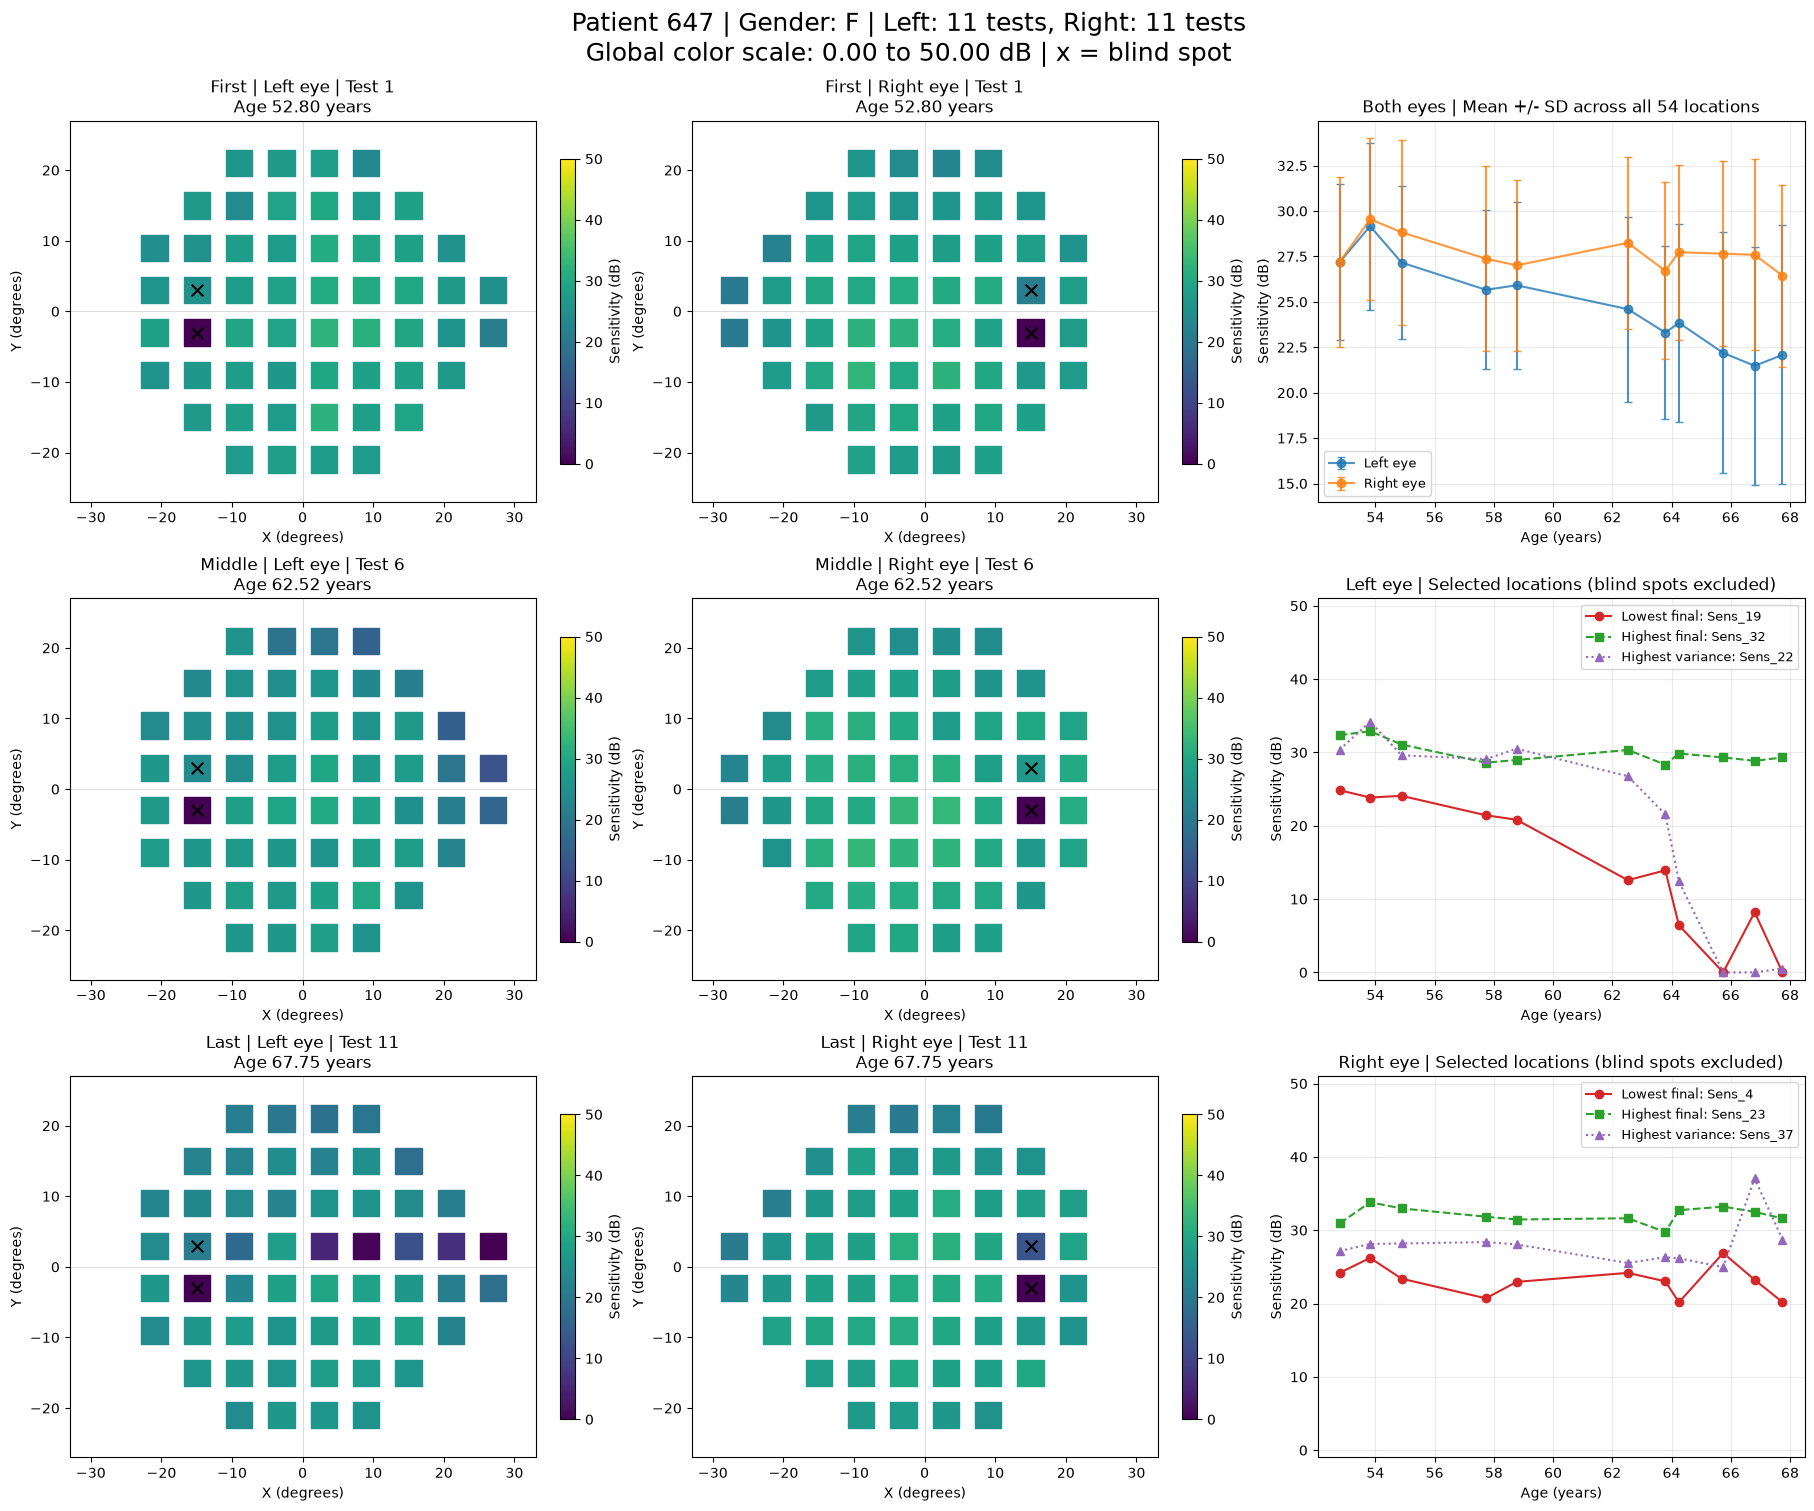

In [85]:
# 3. 視野図6枚と時系列グラフ3枚を、1枚の画像にまとめる
fig, axes = plt.subplots(3, 3, figsize=(18, 15), layout="constrained")
gender = df_patient["Gender"].iloc[0]
if pd.isna(gender):
    gender = "unknown"

fig.suptitle(
    f"Patient {patient_id} | Gender: {gender} | "
    f"Left: {df_eligible.loc[patient_id, 'Left']} tests, "
    f"Right: {df_eligible.loc[patient_id, 'Right']} tests\n"
    f"Global color scale: {sens_min:.2f} to {sens_max:.2f} dB | x = blind spot",
    fontsize=18,
)

for column, eye in enumerate(["Left", "Right"]):
    df_eye = df_patient[df_patient["Eye"] == eye].sort_values("FieldN")
    df_eye = df_eye.reset_index(drop=True)

    # 初回・中央（偶数回なら前側）・最終を、眼ごとに選ぶ。
    l_positions = [0, (len(df_eye) - 1) // 2, len(df_eye) - 1]
    l_visit_labels = ["First", "Middle", "Last"]

    x_coord = df_coord["X"].copy()
    if eye == "Left":
        x_coord = -x_coord

    for row, position in enumerate(l_positions):
        record = df_eye.iloc[position]
        ax = axes[row, column]
        colors = record[l_sens_columns].to_numpy(dtype=float)

        scatter = ax.scatter(
            x_coord, df_coord["Y"], c=colors,
            cmap="viridis", vmin=sens_min, vmax=sens_max,
            marker="s", s=360,
        )
        ax.scatter(
            x_coord[blind_mask], df_coord.loc[blind_mask, "Y"],
            marker="x", color="black", s=70,
        )
        fig.colorbar(scatter, ax=ax, shrink=0.8, label="Sensitivity (dB)")

        age = record["Age"]
        if pd.notna(age) and 0 < age < 90:
            age_text = f"Age {age:.2f} years"
        else:
            age_text = "Age unavailable / capped"
        ax.set_title(
            f"{l_visit_labels[row]} | {eye} eye | Test {int(record['FieldN'])}\n"
            f"{age_text}"
        )
        ax.set(xlabel="X (degrees)", ylabel="Y (degrees)",
               xlim=(-33, 33), ylim=(-27, 27))
        ax.set_aspect("equal")
        ax.axhline(0, color="0.85", linewidth=0.7, zorder=0)
        ax.axvline(0, color="0.85", linewidth=0.7, zorder=0)

    # 右上: 54測定点すべての平均と標準偏差（盲点を含む）。
    time_values = df_eye[time_column]
    mean_values = df_eye[l_sens_columns].mean(axis=1)
    std_values = df_eye[l_sens_columns].std(axis=1, ddof=0)
    eye_color = "tab:blue" if eye == "Left" else "tab:orange"
    axes[0, 2].errorbar(
        time_values, mean_values, yerr=std_values,
        fmt="o-", capsize=3, color=eye_color, alpha=0.8,
        label=f"{eye} eye",
    )

    # 右中央・右下: 盲点を除いた52点から代表点を選ぶ。
    df_sens = df_eye[l_not_blind_columns]
    last_values = df_sens.iloc[-1]
    worst_point = last_values.idxmin()
    best_point = last_values.idxmax()
    variable_point = df_sens.var(axis=0, ddof=0).idxmax()

    ax = axes[column + 1, 2]
    ax.plot(time_values, df_eye[worst_point], "o-", color="tab:red",
            label=f"Lowest final: {worst_point}")
    ax.plot(time_values, df_eye[best_point], "s--", color="tab:green",
            label=f"Highest final: {best_point}")
    ax.plot(time_values, df_eye[variable_point], "^:", color="tab:purple",
            label=f"Highest variance: {variable_point}")
    ax.set_title(f"{eye} eye | Selected locations (blind spots excluded)")
    ax.set_ylim(sens_min - 1, sens_max + 1)

axes[0, 2].set_title("Both eyes | Mean +/- SD across all 54 locations")
# 平均±標準偏差のエラーバーが切れないよう、右上の縦軸は自動調整する。
for ax in axes[:, 2]:
    ax.set_xlabel(time_label)
    ax.set_ylabel("Sensitivity (dB)")
    ax.grid(alpha=0.25)
    ax.legend(fontsize=9)
    if not use_age:
        ax.xaxis.set_major_locator(MaxNLocator(integer=True))

output_dir = Path("imgs")
output_dir.mkdir(exist_ok=True)
output_path = output_dir / f"pat_{patient_id}_overview.png"
fig.savefig(output_path, dpi=150)
print(f"保存先: {output_path}")
plt.show()
plt.close(fig)


## 両眼の感度から、次回の感度を予測するデータを作る

この節のコードセルを上から順に実行します。前の探索・可視化セルの実行は不要です。

- 性別は限定せず、未記録の患者も含めます。左眼・右眼の **両方で4回以上** の検査がある患者を対象にします。
- 患者ごと・眼ごとに `FieldN` 順に並べ、連続する3回を入力、直後の1回を正解にします。
  例えば5回の検査なら「1・2・3回目 → 4回目」と「2・3・4回目 → 5回目」の2サンプルです。
- 入力も正解も **盲点を除く52点の感度（dB）だけ** を使います。
  `Coord_242.csv` の `Cluster != 0` を選び、`LocID` 順に `Sens_番号` を対応させます。
  左右眼ともCSVの同じ測定点順（右眼基準）を使います。
- 左眼と右眼は別サンプルです。1つの入力に左右眼を混ぜません。
  患者ID、左右眼、検査番号は確認用の表に分け、学習用配列には含めません。
- 分割は **患者単位の訓練7割・テスト3割** とし、同じ患者の両眼・全サンプルを同じ側に入れます。
  `random_state=42` で固定します。患者数は整数に丸められ、検査回数にも差があるため、サンプル数の比率は厳密な7:3にはなりません。


In [86]:
# 1. データを読み込み、対象患者と52点の感度列を選ぶ
import pandas as pd
import numpy as np
from sklearn.model_selection import GroupShuffleSplit

df_vf = pd.read_csv("uwhv/CSV/VF_Data.csv")
df_coord = pd.read_csv("uwhv/CSV/Coord_242.csv").sort_values("LocID")

df_not_blind = df_coord[df_coord["Cluster"] != 0]
l_feature_columns = [f"Sens_{loc_id}" for loc_id in df_not_blind["LocID"]]
assert len(l_feature_columns) == 52

# 患者ごとに左眼・右眼の検査回数を数える。
df_counts = df_vf.groupby(["PatID", "Eye"]).size().unstack(fill_value=0)
df_counts = df_counts.reindex(columns=["Left", "Right"], fill_value=0)
df_eligible_counts = df_counts[(df_counts["Left"] >= 4) & (df_counts["Right"] >= 4)]
l_patient_ids = df_eligible_counts.index.tolist()
df_training_vf = df_vf[df_vf["PatID"].isin(l_patient_ids)].copy()

print(f"対象患者: {len(l_patient_ids)}人")
print(f"対象の眼: {len(l_patient_ids) * 2}眼")
print(f"使用する感度: {len(l_feature_columns)}点（盲点を除く）")


対象患者: 1409人
対象の眼: 2818眼
使用する感度: 52点（盲点を除く）


In [ ]:
# 2. 各患者の左右眼から「3回分 → 次の1回分」を作る
l_X = []
l_Y = []
l_sample_info = []

for training_patient_id in l_patient_ids:
    df_training_patient = df_training_vf[df_training_vf["PatID"] == training_patient_id]

    for eye in ["Left", "Right"]:
        df_eye = df_training_patient[df_training_patient["Eye"] == eye].sort_values("FieldN")
        df_eye = df_eye.reset_index(drop=True)

        # 位置は0から数えるため、4回目の位置は3になる。
        for target_position in range(3, len(df_eye)):
            df_input = df_eye.iloc[target_position - 3:target_position]
            target = df_eye.iloc[target_position]

            # 感度だけを数値の配列にする。患者IDや年齢などは含めない。
            l_X.append(df_input[l_feature_columns].to_numpy(dtype=float))
            l_Y.append(target[l_feature_columns].to_numpy(dtype=float))

            # 配列と同じ順番で、分割・確認に使う情報を記録する。
            l_sample_info.append({
                "PatID": training_patient_id,
                "Eye": eye,
                "Input_FieldN": df_input["FieldN"].tolist(),
                "Target_FieldN": int(target["FieldN"]),
            })


### 配列の形とサンプル数を確認する

`np_X` は「サンプル数 × 3回 × 52点」、`np_Y` は「サンプル数 × 52点」です。
`df_sample_info` の各行が、同じ位置の入力・正解に対応します。
各眼の検査がN回なら、作れるサンプル数はN−3です。


In [ ]:
# 3. リストを配列にまとめ、入力・正解・確認用情報の件数を確認する
np_X = np.array(l_X)
np_Y = np.array(l_Y)
df_sample_info = pd.DataFrame(l_sample_info)
np_ids = df_sample_info["PatID"].to_numpy()

expected_samples = int((df_eligible_counts - 3).sum().sum())
assert len(np_X) == len(np_Y) == len(df_sample_info) == expected_samples
assert np_X.shape[1:] == (3, 52)
assert np_Y.shape[1:] == (52,)
assert np.isfinite(np_X).all() and np.isfinite(np_Y).all()

print(f"入力の形: {np_X.shape}")
print(f"正解の形: {np_Y.shape}")
print(df_sample_info.head().to_string(index=False))


入力の形: (9241, 3, 52)
正解の形: (9241, 52)
 PatID   Eye Input_FieldN  Target_FieldN
     1  Left    [1, 2, 3]              4
     1  Left    [2, 3, 4]              5
     1  Left    [3, 4, 5]              6
     1 Right    [1, 2, 3]              4
     1 Right    [2, 3, 4]              5


### 患者単位で訓練・テストに分ける

`GroupShuffleSplit` に、各サンプルの患者IDを `groups` として渡します。
分割で得られる位置番号を、入力・正解・確認用の表に共通して使います。
これにより、両眼や重なりのある3回分の窓が訓練とテストにまたがることを防ぎます。

分割後に使う配列は `np_X_train`、`np_Y_train`、`np_X_test`、`np_Y_test` です。
`df_train_info` と `df_test_info` には、各サンプルに対応する患者・眼・検査番号を残します。


In [ ]:
# 4. 患者単位で7:3に分割する（分割は1回だけ）
gss = GroupShuffleSplit(n_splits=1, train_size=0.7, random_state=42)

for train_index, test_index in gss.split(np_X, np_Y, groups=np_ids):
    np_X_train = np_X[train_index]
    np_Y_train = np_Y[train_index]
    np_X_test = np_X[test_index]
    np_Y_test = np_Y[test_index]

    df_train_info = df_sample_info.iloc[train_index].reset_index(drop=True)
    df_test_info = df_sample_info.iloc[test_index].reset_index(drop=True)


In [ ]:
# 5. 患者の重複、入力と正解の件数、検査の順序を確認する
train_patients = set(df_train_info["PatID"])
test_patients = set(df_test_info["PatID"])
overlap = train_patients & test_patients

assert len(overlap) == 0
assert train_patients | test_patients == set(l_patient_ids)
assert len(np_X_train) == len(np_Y_train) == len(df_train_info)
assert len(np_X_test) == len(np_Y_test) == len(df_test_info)
assert len(np_X_train) + len(np_X_test) == len(np_X)

for sample in l_sample_info:
    fields = sample["Input_FieldN"]
    assert fields[0] < fields[1] < fields[2] < sample["Target_FieldN"]

df_split_summary = pd.DataFrame({
    "区分": ["訓練", "テスト"],
    "患者数": [len(train_patients), len(test_patients)],
    "入力サンプル数": [len(np_X_train), len(np_X_test)],
    "正解サンプル数": [len(np_Y_train), len(np_Y_test)],
})
print(df_split_summary.to_string(index=False))
print(f"訓練とテストの患者重複: {len(overlap)}人")
print(f"訓練の入力・正解: {np_X_train.shape}, {np_Y_train.shape}")
print(f"テストの入力・正解: {np_X_test.shape}, {np_Y_test.shape}")


 区分  患者数  入力サンプル数  正解サンプル数
 訓練  986     6432     6432
テスト  423     2809     2809
訓練とテストの患者重複: 0人
訓練の入力・正解: (6432, 3, 52), (6432, 52)
テストの入力・正解: (2809, 3, 52), (2809, 52)


## 3回平均と最終回の変動量からリッジ回帰を学習する

直前のデータ作成・分割の節を実行してから、この節を上から実行します。

1. 入力 `np_X_train` の3回分を平均し、各測定点の `mean3` を作ります。
2. 3回目の値を `last` とし、`last - mean3` を計算します。
3. `mean3` の52列、その後に `last - mean3` の52列を並べ、104列の特徴量にします。
   どちらの52列も、前の節で作った `l_feature_columns` の測定点順です。
4. 加工済み入力と、次回の52点の感度 `np_Y_train` で `Ridge` を学習します。

感度の単位はdBのままです。正則化の強さは `alpha=1.0`、切片ありとします。
このalphaは今回の設定値で、最適化は行っていません。
各出力点は104個の特徴量すべてを使って予測します。


In [ ]:
# 1. 各サンプルについて、測定点ごとの3回平均と最終回から特徴量を作る
# np_X_train の軸は「サンプル、検査回、測定点」の順番。
np_mean3_train = np_X_train.mean(axis=1)
np_last_train = np_X_train[:, 2, :]
np_change_train = np_last_train - np_mean3_train

# axis=1 で横方向（特徴量の列方向）に結合する。
np_X_train_ridge = np.concatenate([np_mean3_train, np_change_train], axis=1)

assert np_X_train_ridge.shape == (len(np_Y_train), 104)
assert np.isfinite(np_X_train_ridge).all()
print(f"加工前: {np_X_train.shape}")
print(f"加工後: {np_X_train_ridge.shape}")
print(f"正解: {np_Y_train.shape}")


加工前: (6432, 3, 52)
加工後: (6432, 104)
正解: (6432, 52)


In [ ]:
# 2. 加工済みの訓練データと正解を使って、52点を予測するモデルを学習する
from sklearn.linear_model import Ridge

ridge_alpha = 1.0
model_ridge = Ridge(alpha=ridge_alpha, fit_intercept=True)
model_ridge.fit(np_X_train_ridge, np_Y_train)

print(f"学習完了: alpha={model_ridge.alpha}")
print(f"係数の形（出力点数, 特徴量数）: {model_ridge.coef_.shape}")
print(f"切片の形: {model_ridge.intercept_.shape}")


学習完了: alpha=1.0
係数の形（出力点数, 特徴量数）: (52, 104)
切片の形: (52,)


In [ ]:
# 3. 学習に使ったデータで予測し、訓練データ上の誤差を確認する
np_Y_train_pred = model_ridge.predict(np_X_train_ridge)
np_train_error = np_Y_train_pred - np_Y_train

# 全訓練サンプル・全52点をまとめて計算する。
train_rmse = np.sqrt(np.mean(np_train_error ** 2))
train_mae = np.mean(np.abs(np_train_error))

assert np_Y_train_pred.shape == np_Y_train.shape
assert np.isfinite(np_Y_train_pred).all()
print(f"訓練RMSE: {train_rmse:.4f} dB")
print(f"訓練MAE: {train_mae:.4f} dB")
print("これらは訓練データ上の誤差です。未知の患者に対する性能は別途評価します。")


訓練RMSE: 4.0962 dB
訓練MAE: 2.5938 dB
これらは訓練データ上の誤差です。未知の患者に対する性能は別途評価します。


### 学習済みモデルを保存する

学習済みモデルを `models/ridge_mean3_delta.joblib` に保存します。
後で予測するときも、同じ52点の順番で `[mean3, last - mean3]` の104特徴量を作って渡します。


In [ ]:
# 4. 学習済みモデルを保存する
from pathlib import Path
import joblib

model_dir = Path("models")
model_dir.mkdir(exist_ok=True)
model_path = model_dir / "ridge_mean3_delta.joblib"
joblib.dump(model_ridge, model_path)
print(f"モデル保存先: {model_path}")


モデル保存先: models/ridge_mean3_delta.joblib


## mean3とlastをそのまま予測値にする比較用モデル

どちらも学習を必要としない予測関数です。
104特徴量に加工する前の `np_X_train` や `np_X_test` を渡します。
入力は「サンプル数 × 3回 × 52点」、返り値は「サンプル数 × 52点」です。

- `predict_mean3`：各測定点の3回平均を、そのまま次回の感度の予測値にします。
- `predict_last`：3回目の感度を、そのまま次回の感度の予測値にします。

測定点の順番と単位（dB）は入力と同じです。
この節の実行には、前のデータ作成・分割の節で作った配列を使います。


In [ ]:
def predict_mean3(np_X):
    """各測定点の3回平均を、そのまま次回の予測値にする。"""
    if np_X.ndim != 3 or np_X.shape[1:] != (3, 52):
        raise ValueError("入力は（サンプル数, 3回, 52点）の配列にしてください。")

    # axis=1 は検査回の方向。各サンプル・各測定点の3回分を平均する。
    return np_X.mean(axis=1)


def predict_last(np_X):
    """3回目の感度を、そのまま次回の予測値にする。"""
    if np_X.ndim != 3 or np_X.shape[1:] != (3, 52):
        raise ValueError("入力は（サンプル数, 3回, 52点）の配列にしてください。")

    # 0から数えるので、3回目の位置は2。
    # 予測値を後で変更しても元の入力が変わらないよう、コピーを返す。
    return np_X[:, 2, :].copy()


In [ ]:
# 訓練データ・テストデータのそれぞれについて予測値を作る。
np_Y_train_pred_mean3 = predict_mean3(np_X_train)
np_Y_train_pred_last = predict_last(np_X_train)
np_Y_test_pred_mean3 = predict_mean3(np_X_test)
np_Y_test_pred_last = predict_last(np_X_test)

print(f"mean3の予測: 訓練 {np_Y_train_pred_mean3.shape}, テスト {np_Y_test_pred_mean3.shape}")
print(f"lastの予測: 訓練 {np_Y_train_pred_last.shape}, テスト {np_Y_test_pred_last.shape}")


mean3の予測: 訓練 (6432, 52), テスト (2809, 52)
lastの予測: 訓練 (6432, 52), テスト (2809, 52)


## テストデータで3つのモデルの予測誤差を比較する

前のデータ作成・分割の節と、`predict_mean3`・`predict_last` の定義セルを実行してから使います。
リッジ回帰は `models/ridge_mean3_delta.joblib` に保存した学習済みモデルを読み込みます。

1. テスト入力も訓練時と同じ方法で加工します。
   3回平均 `mean3` の52列と、`last - mean3` の52列を、この順番で横に結合します。
2. リッジ回帰には加工後の104特徴量を、`predict_mean3` と `predict_last` には加工前の3回分を渡します。
3. 3モデルの予測を、同じ正解 `np_Y_test` と比較します。

誤差を「予測値 − 正解」とし、全テストサンプル・全52点をまとめて計算します。

- **RMSE**：誤差の2乗を平均してから平方根を取ります。
- **MAE**：誤差の絶対値を平均します。

単位はどちらもdBで、小さいほど予測誤差が小さいことを示します。
各サンプル・各測定点を同じ重みで集計するため、サンプル数が多い患者ほど集計への寄与が大きくなります。


In [ ]:
# 1. テスト入力を、訓練入力と同じ方法・列順で104特徴量に加工する
np_mean3_test = np_X_test.mean(axis=1)
np_last_test = np_X_test[:, 2, :]
np_change_test = np_last_test - np_mean3_test
np_X_test_ridge = np.concatenate([np_mean3_test, np_change_test], axis=1)

assert np_X_test_ridge.shape == (len(np_Y_test), 104)
assert np.isfinite(np_X_test_ridge).all()
print(f"加工前: {np_X_test.shape}")
print(f"加工後: {np_X_test_ridge.shape}")


加工前: (2809, 3, 52)
加工後: (2809, 104)


In [ ]:
# 2. 学習済みリッジ回帰と、2つの比較用モデルで予測する
import joblib

model_ridge = joblib.load("models/ridge_mean3_delta.joblib")
np_Y_test_pred_ridge = model_ridge.predict(np_X_test_ridge)
np_Y_test_pred_mean3 = predict_mean3(np_X_test)
np_Y_test_pred_last = predict_last(np_X_test)

print(f"Ridgeの設定: alpha={model_ridge.alpha}")
print(f"Ridgeの予測: {np_Y_test_pred_ridge.shape}")
print(f"mean3の予測: {np_Y_test_pred_mean3.shape}")
print(f"lastの予測: {np_Y_test_pred_last.shape}")


Ridgeの設定: alpha=1.0
Ridgeの予測: (2809, 52)
mean3の予測: (2809, 52)
lastの予測: (2809, 52)


In [ ]:
# 3. 同じ正解データを使って、RMSEとMAEを計算する
l_test_predictions = [
    ("Ridge", np_Y_test_pred_ridge),
    ("mean3", np_Y_test_pred_mean3),
    ("last", np_Y_test_pred_last),
]
l_test_results = []

assert np.isfinite(np_Y_test).all()
for model_name, np_prediction in l_test_predictions:
    assert np_prediction.shape == np_Y_test.shape
    assert np.isfinite(np_prediction).all()

    np_error = np_prediction - np_Y_test
    # axisを指定しないので、全サンプル・全測定点について平均する。
    rmse = np.sqrt(np.mean(np_error ** 2))
    mae = np.mean(np.abs(np_error))

    l_test_results.append({
        "モデル": model_name,
        "RMSE (dB)": rmse,
        "MAE (dB)": mae,
    })

df_test_results = pd.DataFrame(l_test_results)
print(f"テスト患者: {df_test_info['PatID'].nunique()}人")
print(f"テストサンプル: {len(np_Y_test)}組 / 各サンプル52点")
print(df_test_results.round(4).to_string(index=False))


テスト患者: 423人
テストサンプル: 2809組 / 各サンプル52点
  モデル  RMSE (dB)  MAE (dB)
Ridge     4.1125    2.6157
mean3     4.2927    2.6230
 last     4.8114    2.9041
